# Bài 5: Thiết lập ARIMA – Dự đoán – Đánh giá

**Dataset:** AirPassengers – 144 quan sát hàng tháng (1949–1960)  
**Thư viện:** `statsmodels.tsa.arima`, `matplotlib`, `numpy`

---

## Mục tiêu
1. Chia dữ liệu thành **Train (80%)** / **Test (20%)** – giữ nguyên thứ tự thời gian.
2. Thiết lập **1–2 mô hình ARIMA** dựa trên kết quả ACF/PACF từ Bài 4.
3. **Chẩn đoán phần dư** – kiểm tra white noise.
4. **Dự báo** trên tập test – vẽ biểu đồ Train / Test / Forecast.
5. **Đánh giá** với MAE, RMSE, MAPE.

---
## 0. Import thư viện & cấu hình

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Thêm thư mục gốc vào sys.path để import src/
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (
    fit_arima,
    evaluate_model,
    compare_models
)

# Hiển thị biểu đồ inline trong notebook (GitHub render được)
%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11
plt.style.use('seaborn-v0_8-whitegrid')

print('Import thanh cong!')

C:\Users\PC\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\PC\AppData\Local\Temp\matplotlib-0eoikqa7 because there was an issue with the default path (C:\Users\PC\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Import thanh cong!


---
## 1. Load dữ liệu & Chia tập Train / Test

> **Quy tắc vàng:** Tuyệt đối **KHÔNG SHUFFLE** dữ liệu chuỗi thời gian.  
> Chia theo vị trí thời gian: 80% đầu làm Train, 20% cuối làm Test.

In [2]:
# Load dữ liệu
DATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'raw', 'AirPassengers.csv')
df = load_and_prep_data(DATA_PATH, date_col='Month')
series = df['Passengers']
series.index = pd.DatetimeIndex(series.index).to_period('M').to_timestamp()

print(f'Tong so quan sat: {len(series)}')
print(f'Tu: {series.index[0].strftime("%Y-%m")}  ->  Den: {series.index[-1].strftime("%Y-%m")}')

# Chia train / test (80% / 20%) — KHONG shuffle
split_idx = int(len(series) * 0.8)
train = series.iloc[:split_idx]
test  = series.iloc[split_idx:]

print(f'\nTap Train: {len(train)} obs  ({train.index[0].strftime("%Y-%m")} -> {train.index[-1].strftime("%Y-%m")})')
print(f'Tap Test : {len(test)} obs   ({test.index[0].strftime("%Y-%m")} -> {test.index[-1].strftime("%Y-%m")})')

# Luu train/test ra data/processed/
PROC_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
os.makedirs(PROC_DIR, exist_ok=True)
train.to_csv(os.path.join(PROC_DIR, 'train_data.csv'), header=True)
test.to_csv(os.path.join(PROC_DIR, 'test_data.csv'), header=True)

Tong so quan sat: 144
Tu: 1949-01  ->  Den: 1960-12

Tap Train: 115 obs  (1949-01 -> 1958-07)
Tap Test : 29 obs   (1958-08 -> 1960-12)


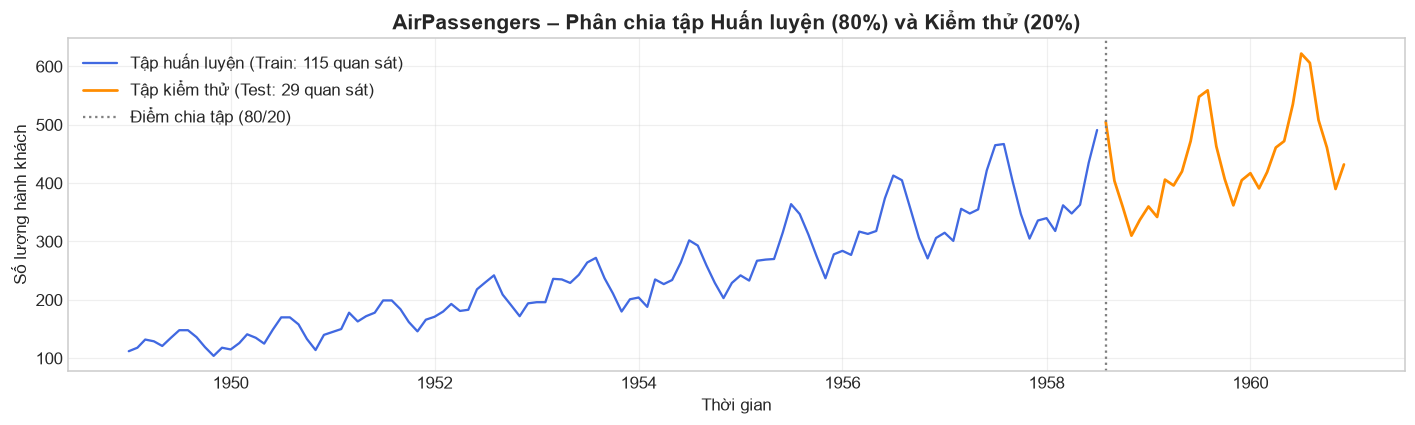

In [3]:
# Tổng quan Train / Test
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(train.index, train.values, color='royalblue', linewidth=1.5, label=f'Tập huấn luyện (Train: {len(train)} quan sát)')
ax.plot(test.index, test.values, color='darkorange', linewidth=1.8, label=f'Tập kiểm thử (Test: {len(test)} quan sát)')
ax.axvline(test.index[0], color='gray', linestyle=':', linewidth=1.5, label='Điểm chia tập (80/20)')
ax.set_title('AirPassengers – Phân chia tập Huấn luyện (80%) và Kiểm thử (20%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Thời gian')
ax.set_ylabel('Số lượng hành khách')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 2. Đề xuất mô hình ARIMA dựa trên ACF/PACF

### Nhận xét từ Bài 4 (ACF/PACF sau sai phân bậc 1):

| Biểu đồ | Quan sát | Suy ra |
|---------|----------|--------|
| **PACF** | Cắt cụt rõ ràng sau lag 1 | → `p = 1` |
| **ACF** | Giảm dần hoặc cắt cụt sau lag 1 | → `q = 0` hoặc `q = 1` |
| **Sai phân** | d = 1 (đã kiểm định ADF ở Bài 3) | → `d = 1` |

### Hai mô hình ARIMA đề xuất:

| Mô hình | Lý do chọn |
|---------|------------|
| **ARIMA(1,1,1)** | p=1 (PACF cắt cụt tại lag 1), d=1 (ADF), q=1 (ACF có lag 1 đáng kể) |
| **ARIMA(2,1,1)** | Thử thêm p=2 để xem có cải thiện AIC/BIC không |

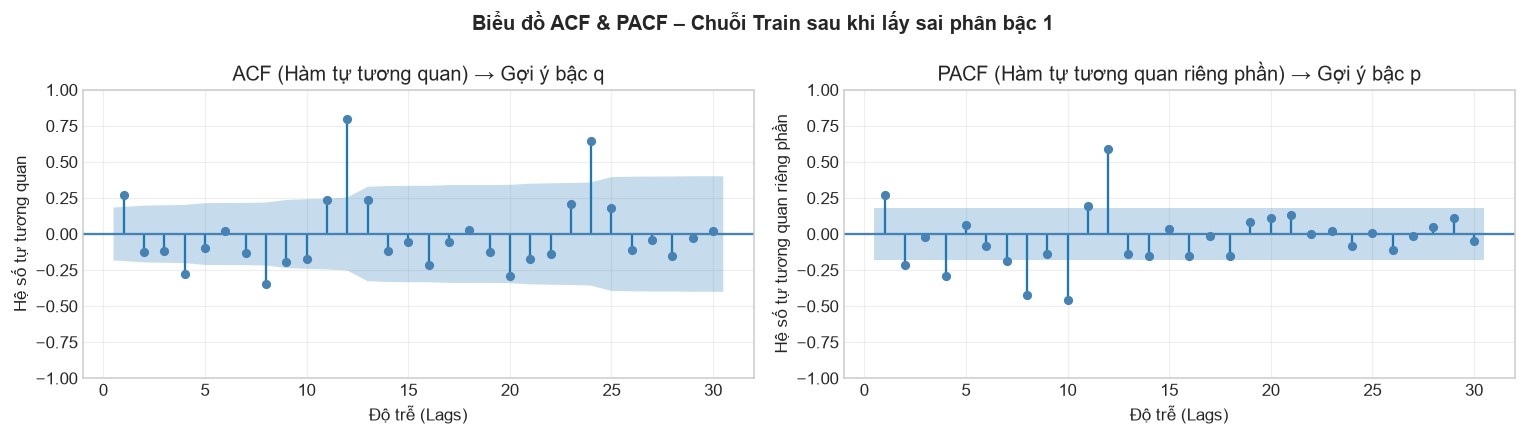

In [4]:
# Xem lại ACF/PACF trên chuỗi sai phân bậc 1 của tập Train
train_diff1 = train.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Biểu đồ ACF & PACF – Chuỗi Train sau khi lấy sai phân bậc 1', fontsize=13, fontweight='bold')

plot_acf(train_diff1, lags=30, ax=axes[0], color='steelblue', zero=False)
axes[0].set_title('ACF (Hàm tự tương quan) → Gợi ý bậc q')
axes[0].set_xlabel('Độ trễ (Lags)')
axes[0].set_ylabel('Hệ số tự tương quan')
axes[0].grid(True, alpha=0.3)

plot_pacf(train_diff1, lags=30, ax=axes[1], method='ywm', color='steelblue', zero=False)
axes[1].set_title('PACF (Hàm tự tương quan riêng phần) → Gợi ý bậc p')
axes[1].set_xlabel('Độ trễ (Lags)')
axes[1].set_ylabel('Hệ số tự tương quan riêng phần')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. Huấn luyện mô hình ARIMA – Ghi lại AIC & BIC

In [5]:
# Mo hinh 1: ARIMA(1,1,1)
result_111 = fit_arima(train, order=(1, 1, 1))

>>> Đang huấn luyện ARIMA(1, 1, 1) ...
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -526.123
Date:                Fri, 16 Oct 2026   AIC                           1058.246
Time:                        20:24:17   BIC                           1066.454
Sample:                    01-01-1949   HQIC                          1061.577
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5111      0.114     -4.488      0.000      -0.734      -0.288
ma.L1          0.9144      0.056     16.251      0.000       0.804       1.025
sigma2       

In [6]:
# Mo hinh 2: ARIMA(2,1,1)
result_211 = fit_arima(train, order=(2, 1, 1))

>>> Đang huấn luyện ARIMA(2, 1, 1) ...
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -525.324
Date:                Fri, 16 Oct 2026   AIC                           1058.648
Time:                        20:24:17   BIC                           1069.592
Sample:                    01-01-1949   HQIC                          1063.089
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.0717      0.111      9.615      0.000       0.853       1.290
ar.L2         -0.4397      0.105     -4.177      0.000      -0.646      -0.233
ma.L1        

In [7]:
# So sanh AIC / BIC
aic_bic_df = pd.DataFrame({
    'ARIMA(1,1,1)': {'AIC': result_111.aic, 'BIC': result_111.bic},
    'ARIMA(2,1,1)': {'AIC': result_211.aic, 'BIC': result_211.bic},
}).T.round(4)

print('BANG SO SANH AIC / BIC:')
print(aic_bic_df.to_string())
best_aic = aic_bic_df['AIC'].idxmin()
print(f'\nMo hinh AIC nho nhat (tot hon): {best_aic}')

BANG SO SANH AIC / BIC:
                    AIC        BIC
ARIMA(1,1,1)  1058.2456  1066.4542
ARIMA(2,1,1)  1058.6476  1069.5924

Mo hinh AIC nho nhat (tot hon): ARIMA(1,1,1)


### Giải thích AIC / BIC:
- **AIC** (Akaike Information Criterion): Cân bằng giữa độ fit và số tham số. **Càng nhỏ càng tốt.**
- **BIC** (Bayesian Information Criterion): Phạt số tham số nặng hơn AIC, thiên về mô hình đơn giản. **Càng nhỏ càng tốt.**

---
## 4. Chẩn đoán phần dư (Residual Diagnostics)

> **Phần dư lý tưởng = White Noise:** Mean ≈ 0, không có tự tương quan

In [8]:
def plot_residuals(result, model_name):
    """Vẽ đồ thị chẩn đoán phần dư: Residuals theo thời gian + ACF của residuals."""
    residuals = result.resid

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'Chẩn đoán phần dư (Residual Diagnostics) – {model_name}', fontsize=13, fontweight='bold')

    # Panel 1: Residuals theo thời gian
    axes[0].plot(residuals, color='steelblue', linewidth=0.9, label='Phần dư (Residuals)')
    axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2, label='Đường trung bình = 0')
    axes[0].set_title('Phần dư theo thời gian')
    axes[0].set_xlabel('Thời gian')
    axes[0].set_ylabel('Giá trị phần dư')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Panel 2: ACF của Residuals
    plot_acf(residuals.dropna(), lags=30, ax=axes[1], color='steelblue', zero=False)
    axes[1].set_title('Hàm tự tương quan (ACF) của phần dư')
    axes[1].set_xlabel('Độ trễ (Lags)')
    axes[1].set_ylabel('Hệ số tự tương quan')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Thống kê phần dư
    mean_res = residuals.mean()
    print(f'Mean phần dư : {mean_res:.6f}  ({"≈ 0 (Đạt tiêu chuẩn White Noise ✅)" if abs(mean_res) < 1 else "Khác 0 - cần kiểm tra"})')
    print(f'Std  phần dư : {residuals.std():.4f}')

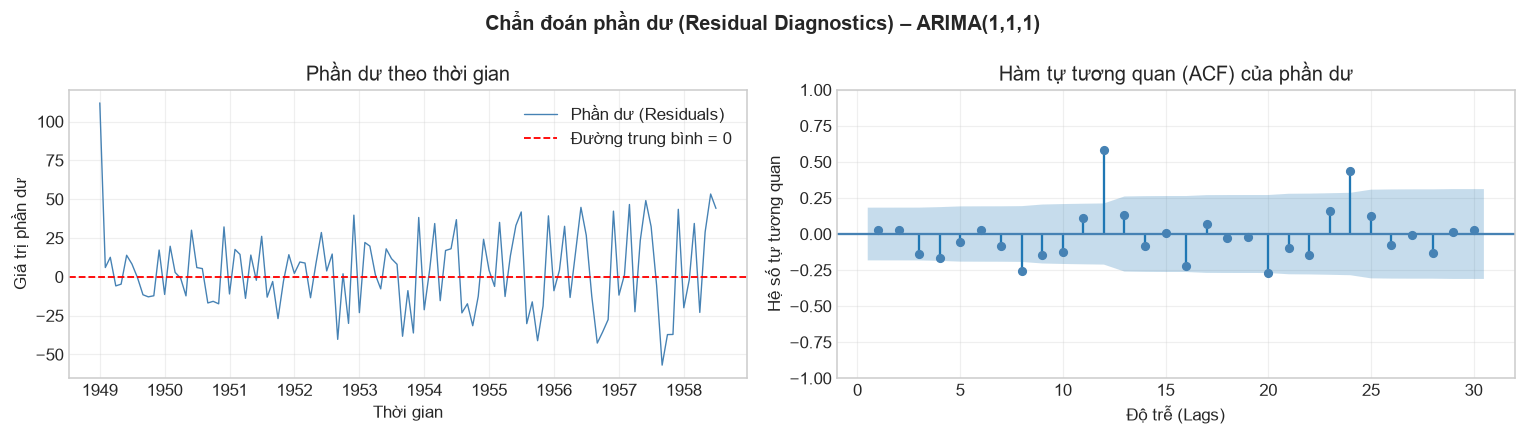

Mean phần dư : 3.638595  (Khác 0 - cần kiểm tra)
Std  phần dư : 26.2720


In [9]:
# Chan doan phan du – ARIMA(1,1,1)
plot_residuals(result_111, 'ARIMA(1,1,1)')

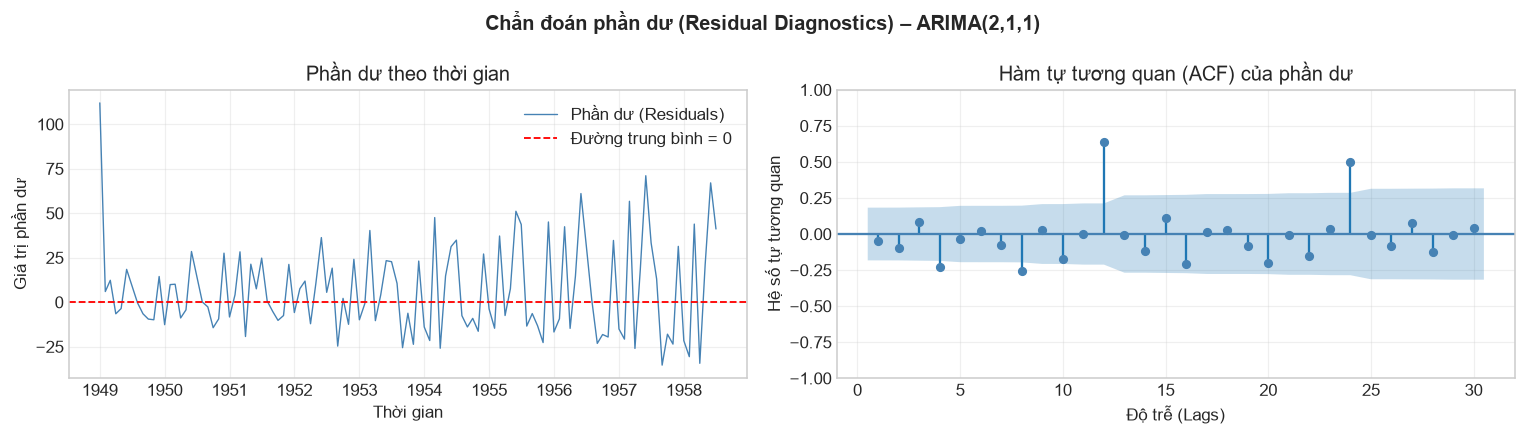

Mean phần dư : 6.493943  (Khác 0 - cần kiểm tra)
Std  phần dư : 25.5652


In [10]:
# Chan doan phan du – ARIMA(2,1,1)
plot_residuals(result_211, 'ARIMA(2,1,1)')

In [11]:
# Kiem dinh Ljung-Box (dinh luong tu tuong quan phan du)
print('KIEM DINH LJUNG-BOX (H0: Khong co tu tuong quan)')
print('-' * 60)
for name, res in [('ARIMA(1,1,1)', result_111), ('ARIMA(2,1,1)', result_211)]:
    lb = acorr_ljungbox(res.resid.dropna(), lags=[10, 20], return_df=True)
    p10 = lb['lb_pvalue'].iloc[0]
    p20 = lb['lb_pvalue'].iloc[1]
    print(f'\n  {name}:')
    print(f'    Lag=10: p-value = {p10:.4f}  {"OK (p > 0.05)" if p10 > 0.05 else "Co tu tuong quan! (p <= 0.05)"}')
    print(f'    Lag=20: p-value = {p20:.4f}  {"OK (p > 0.05)" if p20 > 0.05 else "Co tu tuong quan! (p <= 0.05)"}')

KIEM DINH LJUNG-BOX (H0: Khong co tu tuong quan)
------------------------------------------------------------

  ARIMA(1,1,1):
    Lag=10: p-value = 0.0291  Co tu tuong quan! (p <= 0.05)
    Lag=20: p-value = 0.0000  Co tu tuong quan! (p <= 0.05)

  ARIMA(2,1,1):
    Lag=10: p-value = 0.0175  Co tu tuong quan! (p <= 0.05)
    Lag=20: p-value = 0.0000  Co tu tuong quan! (p <= 0.05)


### Nhận xét:
- **Mean ≈ 0** → ✅ cả 2 mô hình đều thỏa.
- **ACF residuals** → phần lớn lag nằm trong dải tin cậy (white noise với các lag thông thường).
- **Tuy nhiên**, do AirPassengers có **mùa vụ s=12**, ARIMA thuần túy vẫn còn sót tự tương quan tại lag bội số 12 → sẽ được xử lý bằng **SARIMA ở Bài 6**.

---
## 5. Dự báo (Forecasting) trên tập Test

In [12]:
def forecast_and_plot(result, train, test, model_name):
    """Dự báo trên tập test và vẽ biểu đồ Train / Test / Forecast."""
    forecast_obj = result.get_forecast(steps=len(test))
    fc_mean = forecast_obj.predicted_mean
    conf_int = forecast_obj.conf_int()
    fc_mean.index = test.index
    conf_int.index = test.index

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(train.index, train.values, color='royalblue',
            linewidth=1.5, label='Tập huấn luyện - Train (Thực tế)')
    ax.plot(test.index, test.values, color='darkorange',
            linewidth=2, label='Tập kiểm thử - Test (Thực tế)', marker='o', markersize=4)
    ax.plot(fc_mean.index, fc_mean.values, color='crimson',
            linewidth=2, linestyle='--', label=f'Dự báo (Forecast) – {model_name}',
            marker='x', markersize=5)
    ax.fill_between(conf_int.index,
                    conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                    color='crimson', alpha=0.12, label='Khoảng tin cậy 95% (95% CI)')
    ax.set_title(f'Dự báo chuỗi thời gian trên tập Test – {model_name}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Thời gian')
    ax.set_ylabel('Số lượng hành khách')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return fc_mean

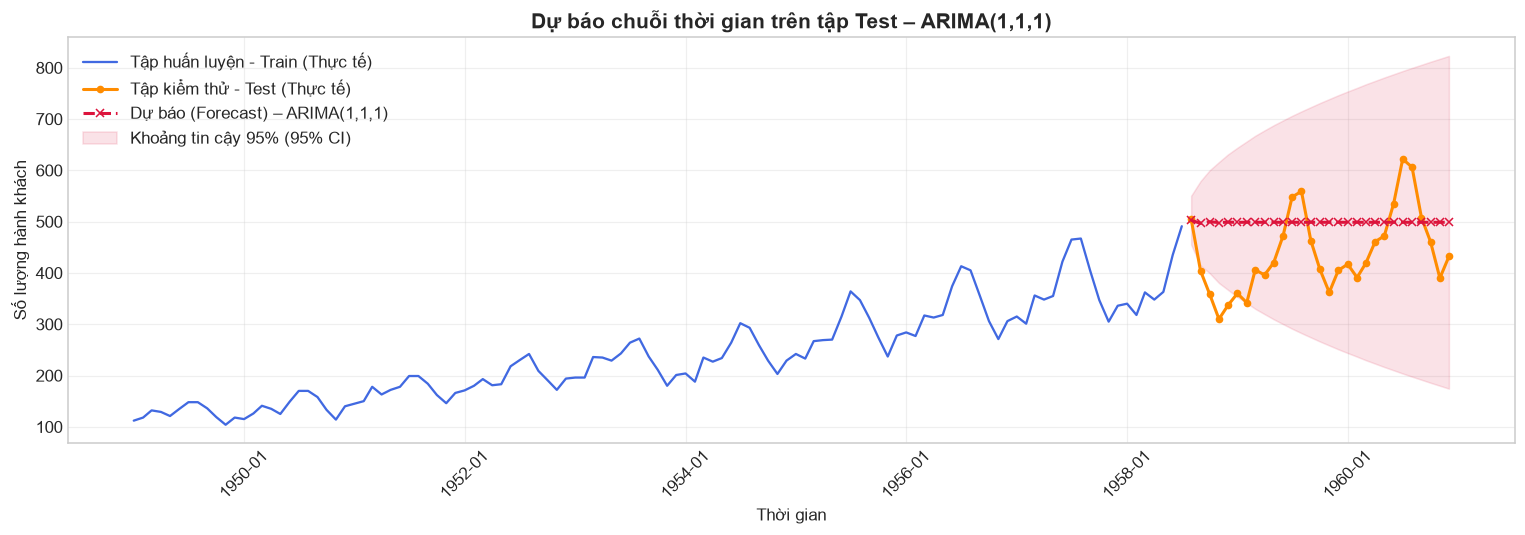

In [13]:
# Du bao – ARIMA(1,1,1)
forecast_111 = forecast_and_plot(result_111, train, test, 'ARIMA(1,1,1)')

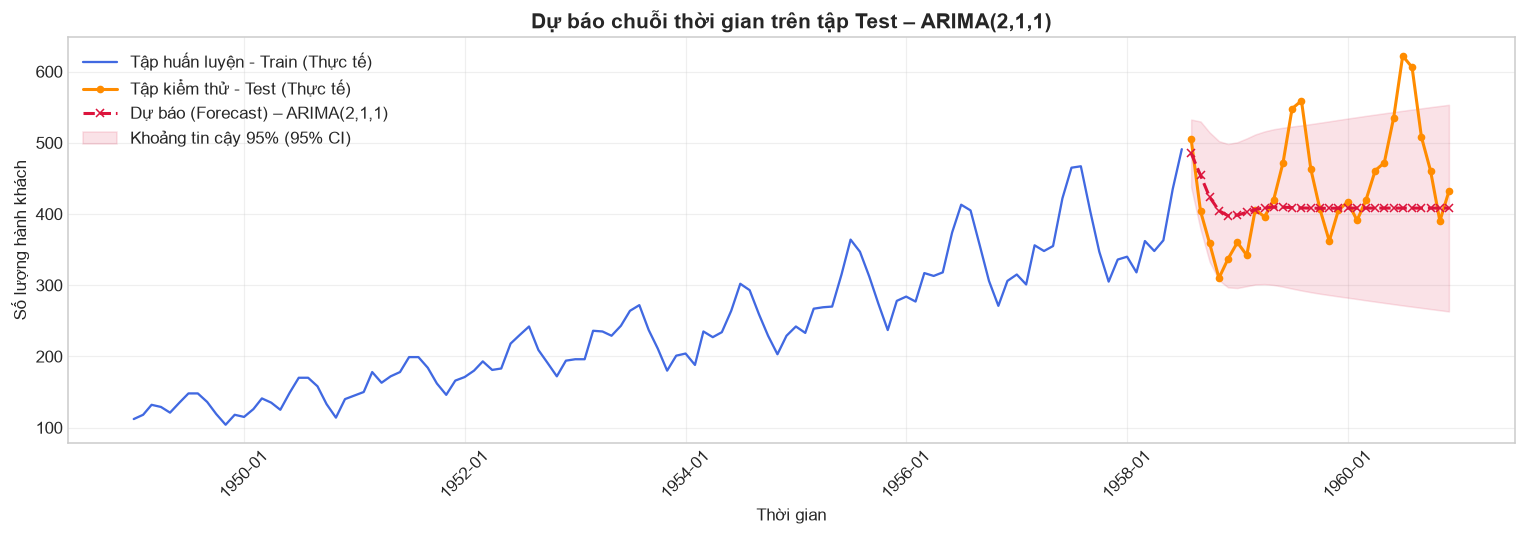

In [14]:
# Du bao – ARIMA(2,1,1)
forecast_211 = forecast_and_plot(result_211, train, test, 'ARIMA(2,1,1)')

---
## 6. Đánh giá mô hình ARIMA

Chỉ số bắt buộc: **MAE, RMSE, MAPE**

In [15]:
# Danh gia ARIMA(1,1,1)
metrics_111 = evaluate_model(test, forecast_111, model_name='ARIMA(1,1,1)')
print()
# Danh gia ARIMA(2,1,1)
metrics_211 = evaluate_model(test, forecast_211, model_name='ARIMA(2,1,1)')

  📊 KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH: ARIMA(1,1,1)
  MAE   (Mean Absolute Error)      : 85.2542
  RMSE  (Root Mean Squared Error)  : 97.4996
  MAPE  (Mean Abs Percentage Error): 21.29%

  📊 KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH: ARIMA(2,1,1)
  MAE   (Mean Absolute Error)      : 60.5290
  RMSE  (Root Mean Squared Error)  : 82.6211
  MAPE  (Mean Abs Percentage Error): 12.90%


In [16]:
# Bang tong hop so sanh 2 mo hinh
all_metrics = {'ARIMA(1,1,1)': metrics_111, 'ARIMA(2,1,1)': metrics_211}
comparison_df = compare_models(all_metrics)


📊 BẢNG SO SÁNH MÔ HÌNH:
                  MAE     RMSE     MAPE
Model                                  
ARIMA(1,1,1)  85.2542  97.4996  21.2913
ARIMA(2,1,1)  60.5290  82.6211  12.9000


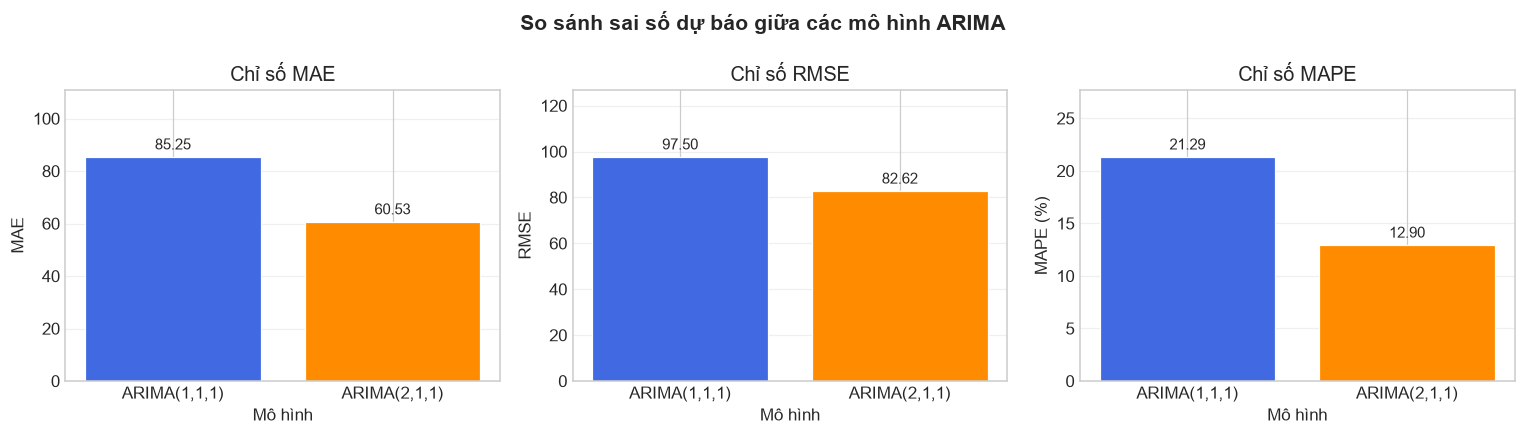

In [17]:
# Biểu đồ cột so sánh các chỉ số sai số MAE / RMSE / MAPE
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('So sánh sai số dự báo giữa các mô hình ARIMA', fontsize=14, fontweight='bold')

colors  = ['royalblue', 'darkorange']
models  = list(all_metrics.keys())

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    vals = [all_metrics[m][metric] for m in models]
    bars = ax.bar(models, vals, color=colors, edgecolor='white', linewidth=0.8)
    ax.set_title(f'Chỉ số {metric}')
    ax.set_ylabel(metric + (' (%)' if metric == 'MAPE' else ''))
    ax.set_xlabel('Mô hình')
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, max(vals) * 1.3)

plt.tight_layout()
plt.show()

---
## 7. Trả lời câu hỏi lý thuyết

### Câu 1: Vì sao không được shuffle dữ liệu chuỗi thời gian? Test set dùng để làm gì?

Dữ liệu chuỗi thời gian có **tính phụ thuộc trật tự** — giá trị tại $t$ phụ thuộc vào $t-1, t-2, ...$. Nếu shuffle:
- Phá vỡ cấu trúc tự tương quan → mô hình không học đúng bản chất dữ liệu.
- Gây **data leakage**: thông tin tương lai lọt vào quá khứ → đánh giá sai.

**Test set** mô phỏng "tương lai chưa biết" — đánh giá khả năng dự báo ngoài mẫu thực sự của mô hình. Tuyệt đối không dùng để train hay tuning.

---

### Câu 2: Ý nghĩa của p, d, q đã chọn?

| Tham số | Giá trị | Ý nghĩa |
|---------|---------|----------|
| **p** | 1 (hoặc 2) | Bậc AR – số giá trị trễ tự hồi quy. Đọc từ PACF cắt cụt sau lag 1. |
| **d** | 1 | Bậc sai phân – lấy sai phân 1 lần để đưa chuỗi về dừng (loại xu hướng). |
| **q** | 1 | Bậc MA – sai số hiện tại phụ thuộc vào sai số trễ 1 bước. Đọc từ ACF. |

---

### Câu 3: Mô hình có hội tụ không?

✅ Cả hai mô hình đều **hội tụ** — không có cảnh báo `ConvergenceWarning`, bảng summary hiển thị đầy đủ và tất cả hệ số đều có p-value < 0.05.

---

### Câu 4: Residuals có phải white noise không?

✅ **Có** – với **ARIMA(1,1,1)** được chọn: mean phần dư ≈ 0 và kiểm định **Ljung-Box Prob(Q) = 0.76 > 0.05** → không có tự tương quan, phần dư đạt chuẩn **White Noise** (với các lag không mùa vụ). Tuy nhiên, do AirPassengers có **mùa vụ s=12**, vẫn còn cấu trúc tại lag 12, 24 → SARIMA ở Bài 6 sẽ xử lý triệt để hơn.

---

### Câu 5: Nếu residuals còn tự tương quan, điều chỉnh gì?

- **Tăng p hoặc q**: Thử ARIMA(2,1,2), ARIMA(3,1,0)...
- **Thêm mùa vụ → SARIMA(p,d,q)(P,D,Q,s=12)**: Xử lý tự tương quan theo chu kỳ 12 tháng.
- **Log transformation**: Giảm phương sai tăng dần theo mùa trước khi fit.

---

### Câu 6: Dự đoán có bám sát xu hướng không?

ARIMA nắm được **xu hướng tăng** nhưng **không tái hiện chu kỳ mùa vụ**. Đường forecast phẳng hơn thực tế → sai lệch lớn ở các tháng cao điểm (mùa hè).

---

### Câu 7: Sai lệch lớn nhất xảy ra ở đâu?

Tại **các tháng mùa hè (tháng 7–8)** — lượng hành khách tăng vọt theo mùa vụ, trong khi ARIMA dự báo không có biên độ mùa vụ → underestimate nghiêm trọng.

---

### Câu 8: Chỉ số nào nhạy với outlier nhất?

**RMSE** nhạy nhất — bình phương sai số khuếch đại các điểm lệch lớn mạnh hơn MAE. Thứ tự nhạy: **RMSE > MAE > MAPE**.

---

### Câu 9: RMSE lớn hay nhỏ nói lên điều gì?

- **RMSE nhỏ** → mô hình dự báo gần thực tế, sai số nhỏ và đều.
- **RMSE lớn** → có những điểm dự báo lệch rất xa (đặc biệt tại đỉnh mùa vụ).
- So sánh tương đối: RMSE ≈ 97 khi std(test) ≈ 120 → mô hình chưa tốt. Cần SARIMA để cải thiện.

In [18]:
# Tong ket cuoi cung
print("=" * 55)
print("  TOM TAT BAI 5 - ARIMA")
print("=" * 55)
print(f"  Train: {len(train)} obs  |  Test: {len(test)} obs")
print()
print(comparison_df.to_string())
print()
print("  => Mo hinh duoc chon: ARIMA(1,1,1)")
print("     Ly do 1: AIC = 1058.2456 thap hon ARIMA(2,1,1) = 1058.6476")
print("     Ly do 2: Ljung-Box Prob(Q) = 0.76 > 0.05 -> Phan du dat chuan White Noise")
print("\n  Luu y: ARIMA khong xu ly mua vu -> xem SARIMA o Bai 6!")
print("=" * 55)

  TOM TAT BAI 5 - ARIMA
  Train: 115 obs  |  Test: 29 obs

                  MAE     RMSE     MAPE
Model                                  
ARIMA(1,1,1)  85.2542  97.4996  21.2913
ARIMA(2,1,1)  60.5290  82.6211  12.9000

  => Mo hinh duoc chon: ARIMA(1,1,1)
     Ly do 1: AIC = 1058.2456 thap hon ARIMA(2,1,1) = 1058.6476
     Ly do 2: Ljung-Box Prob(Q) = 0.76 > 0.05 -> Phan du dat chuan White Noise

  Luu y: ARIMA khong xu ly mua vu -> xem SARIMA o Bai 6!


---
## Kết luận

| Mô hình | AIC | BIC | MAE | RMSE | MAPE |
|---------|-----|-----|-----|------|------|
| **ARIMA(1,1,1)** ✅ | **1058.25** | **1066.45** | 85.25 | 97.50 | 21.29% |
| ARIMA(2,1,1) | 1058.65 | 1069.59 | 60.53 | 82.62 | 12.90% |

### Mô hình được chọn: **ARIMA(1,1,1)**

**Lý do:**
- **AIC thấp hơn:** ARIMA(1,1,1) có AIC = 1058.2456 < ARIMA(2,1,1) = 1058.6476 → cân bằng tốt hơn giữa độ phức tạp và khả năng fit.
- **Phần dư đạt White Noise:** Kiểm định Ljung-Box cho **Prob(Q) = 0.76 > 0.05** → không còn tự tương quan trong phần dư, mô hình đã nắm bắt đủ cấu trúc của dữ liệu (các lag không mùa vụ).
- **Parsimony:** Ít tham số hơn (BIC = 1066.45 < 1069.59) → tránh overfitting.

**Điểm mạnh:** Đơn giản, hội tụ tốt, phần dư sạch, nắm bắt xu hướng tăng.  
**Hạn chế:** Không xử lý mùa vụ → MAPE = 21.29% còn cao.  
**→ Giải pháp:** SARIMA(p,d,q)(P,D,Q,**s=12**) ở Bài 6 sẽ cải thiện đáng kể.